In [1]:
import pacmap 
import numpy        as np
import pandas       as pd
import umap.umap_   as umap

from tqdm                               import tqdm
from sklearn.preprocessing              import StandardScaler, MinMaxScaler
from sklearn.cluster                    import DBSCAN

from utils.Preprocessing                import PreProcessData
from utils.plotFigures                  import linePlot, lineAndScatterPlot, scatterPlot3D, scatterPlot2D
#from clustering.clusteringTimeSeries    import ClusteringTimeSeries
from clustering.plotClustering          import ClusteringResults

# Preprocessing

In [2]:
preData = PreProcessData()
preData.dataLoading(typeFile='h5')
df      = preData.splitTimeSeries()

scaler  = MinMaxScaler() 
preData.normalizeData(scaler);

## Split time series graph

In [3]:
linePlot(data   = df, 
         x      = 'tiempo', 
         y      = 'corriente(A)', 
         color  = 'trajectory')

# Clustering

In [4]:
# Declarate models for clustering and dimensionality reduction for manipulable variables

dfManipulableVar = preData.scaledCrusher1[preData.manipulatedCr1]

clusteringModels    = {'umap':   DBSCAN(min_samples = 150,
                                        eps         = 2.2,  
                                        n_jobs      = -1),

                       'pacmap': DBSCAN(min_samples = 200,
                                        eps         = 3,   
                                        n_jobs      = -1)} 

dimReductionModels  = {'umap':   umap.UMAP(n_components = 2, 
                                           random_state = 40),

                       'pacmap': pacmap.PaCMAP(n_components = 2, 
                                               random_state = 40, 
                                               save_tree    = True)}

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\mmodal\Lib\site-packages\pacmap\pacmap.py:828: UserWarning:




In [5]:
Clusters = ClusteringResults(data                = preData.crusher1, 
                             dataNormalized      = dfManipulableVar, 
                             clusteringModels    = clusteringModels, 
                             dimReductionModels  = dimReductionModels)

In [6]:
# Train dimensinality reduction models wiht a trajectory
Clusters.train(trainTrajectory='15')

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\mmodal\Lib\site-packages\umap\umap_.py:1945: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



In [7]:
# Clusters are calculated in embedding space for each trajectory
for trajectory in tqdm(Clusters.trajectories):
    Clusters.getResults(trajectory)

100%|██████████| 25/25 [04:36<00:00, 11.05s/it]


## Graphs of the results

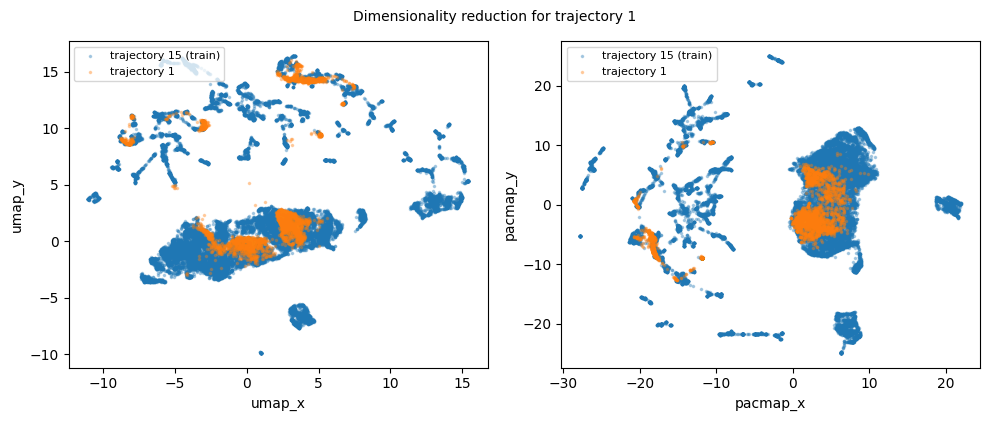

In [8]:
Clusters.plotEmbedding(nfigures=1)

### Comparison of clusters by dimensionality reduction algorithm

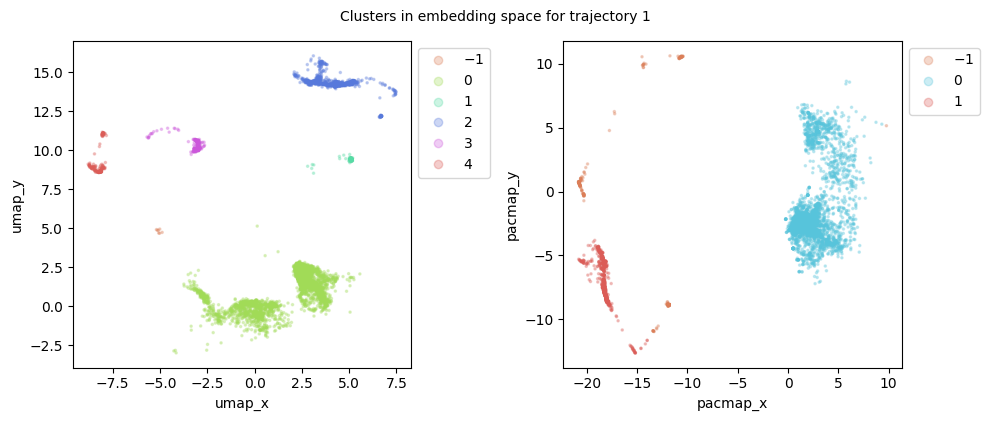

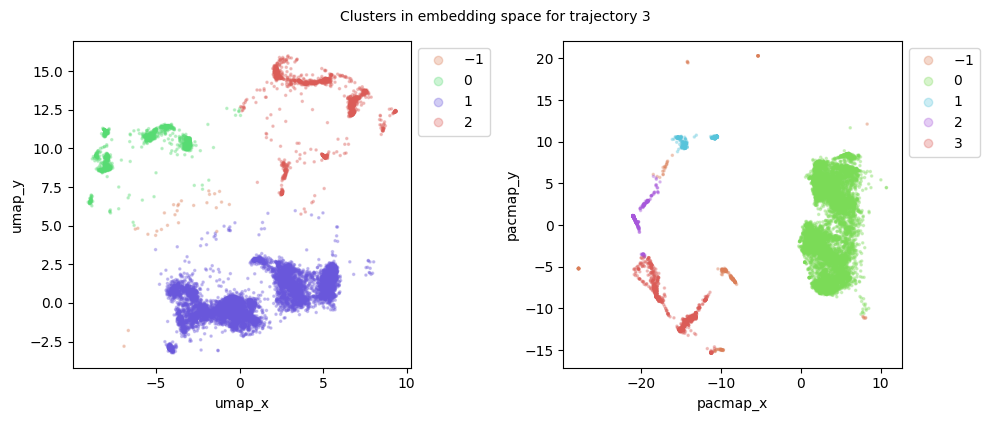

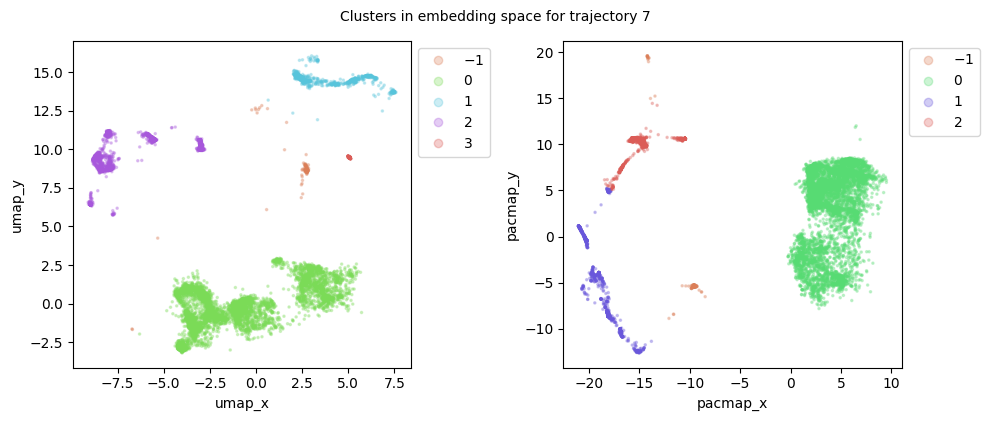

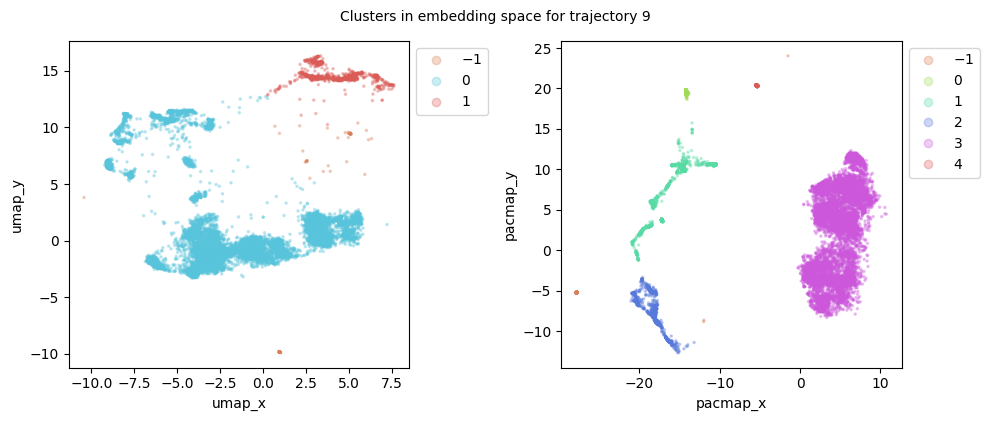

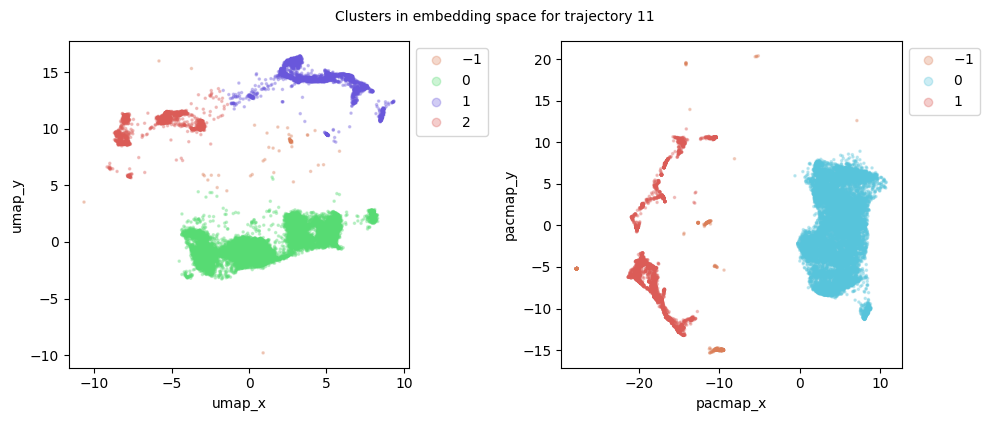

...

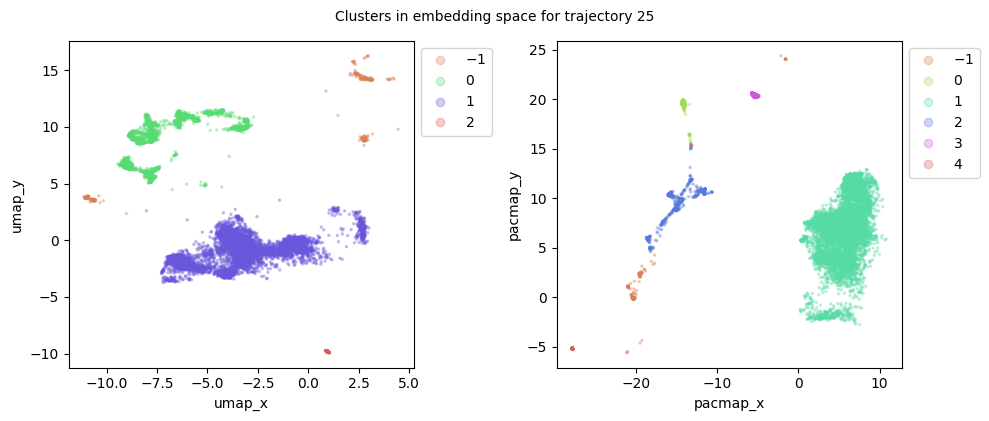

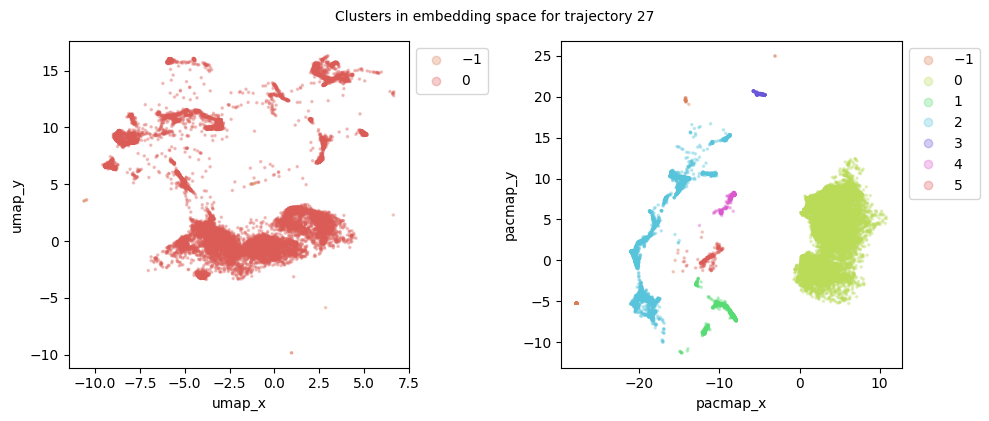

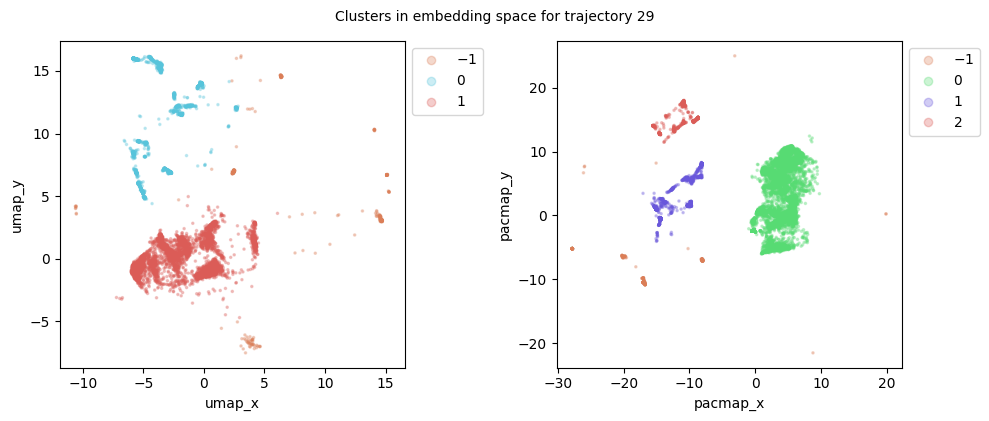

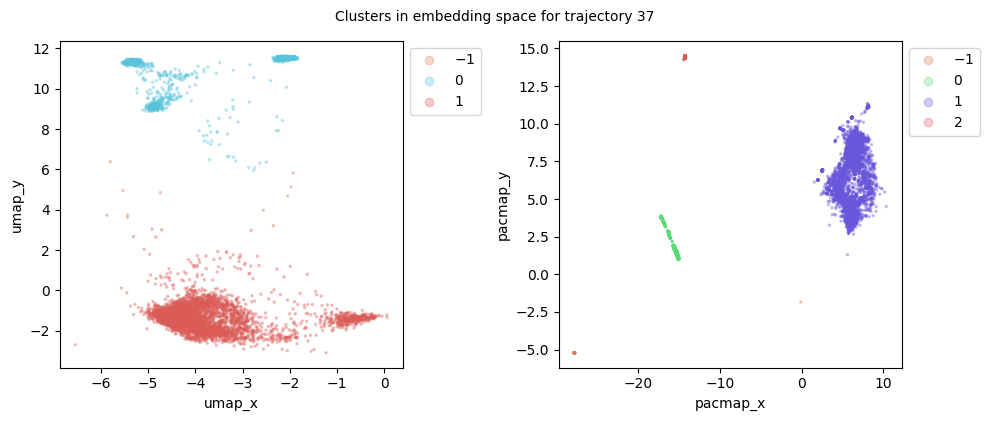

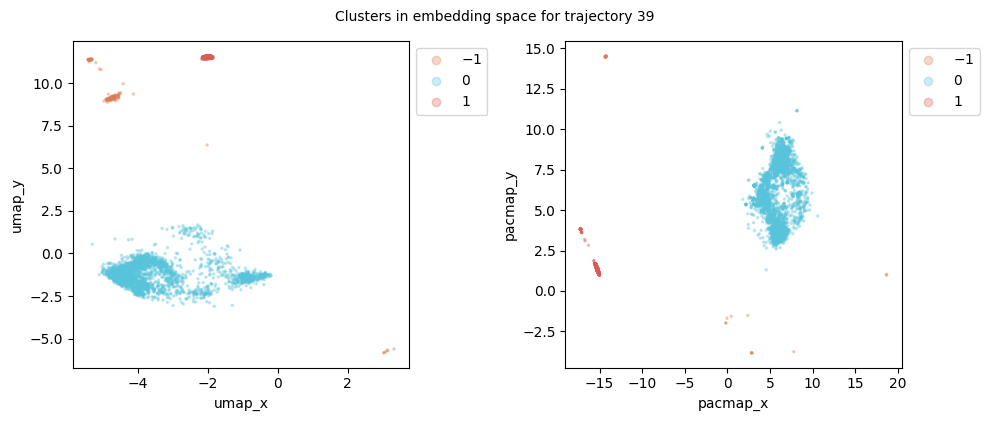

In [21]:
Clusters.plotResults(nfigures=15)

### Clusters in embedding space

In [10]:
Clusters.plotFigure('scatter2D', 
                    idxTrajectory   = 5, 
                    idxVariable     = 10, 
                    algorithm       = 'pacmap')

### Time series colored by clusters

In [11]:
Clusters.plotFigure('lineplot', 
                    idxTrajectory   = 3, 
                    idxVariable     = 0, 
                    algorithm       = 'pacmap')

# Clusters Comparison

In [12]:
dfSimilarClusters = Clusters.getSimilarClusters(algorithm = 'pacmap', 
                                                threshold = 5)

In [13]:
idxGroupCluster = 10
scatterPlot2D(data  = dfSimilarClusters[dfSimilarClusters['group']==idxGroupCluster], 
              x     = 'pacmap_x', 
              y     = 'pacmap_y',
              #z     = 'pacmap_z', 
              color = 'label',
              title = 'Similar clusters')

## Unified Clusters

In [14]:
Clusters.getSimilarClusters(algorithm = 'umap', threshold = 5)
Clusters.unifyClusters(algorithm='umap')

Clusters.getSimilarClusters(algorithm = 'pacmap', threshold = 5)
Clusters.unifyClusters(algorithm='pacmap')

In [20]:
len(Clusters.connectedComponents)

10

### Relationship between clusters of trajectories

In [29]:
import matplotlib.pyplot as plt
import networkx as nx

In [59]:
def plotGraph():
    # Assign colors to nodes based on the connected component they belong to
    colors      = ['red', 'royalblue', 'green', 'orange', 'purple', 'yellow'] # Change length of colors
    nodeColors = {}
    edgeColors = {}

    for i, component in enumerate(Clusters.connectedComponents):

        # Add colors to node and edges
        for node in component:
            nodeColors[node] = colors[i % len(colors)]

        for edge in Clusters.Graph.edges():
                if edge[0] in component and edge[1] in component:
                    edgeColors[edge] = colors[i % len(colors)]

    # Add position to graph        
    pos = {}
    for node in Clusters.Graph.nodes():
        pos[node] = (node[0], node[1])

    # Create figure
    plt.figure(figsize  = (8, 6))
    nx.draw(G           = Clusters.Graph, 
            pos         = pos, 
            with_labels = True, 
            node_size   = 400, 
            font_size   = 6, 
            arrowsize   = 10,
            node_color  = [nodeColors[node] for node in Clusters.Graph.nodes()],  
            edge_color  = [edgeColors[edge] for edge in Clusters.Graph.edges()], 
            )

    plt.xlabel('trajectories')
    plt.ylabel('clusters')
    plt.title("Assignment found between similar clusters")
    plt.show()

In [61]:
import plotly.graph_objects as go

def plotGraph():
    # Assign colors to nodes based on the connected component they belong to
    colors = ['red', 'royalblue', 'green', 'orange', 'purple', 'yellow'] # Change length of colors
    nodeColors = {}
    edgeColors = {}

    for i, component in enumerate(Clusters.connectedComponents):

        # Add colors to node and edges
        for node in component:
            nodeColors[node] = colors[i % len(colors)]

        for edge in Clusters.Graph.edges():
            if edge[0] in component and edge[1] in component:
                edgeColors[edge] = colors[i % len(colors)]

    # Add position to graph
    pos = {}
    for node in Clusters.Graph.nodes():
        pos[node] = (node[0], node[1])

    # Create traces for nodes
    node_trace = go.Scatter(
        x=[pos[node][0] for node in Clusters.Graph.nodes()],
        y=[pos[node][1] for node in Clusters.Graph.nodes()],
        mode='markers',
        marker=dict(
            size=20,
            color=[nodeColors[node] for node in Clusters.Graph.nodes()],
        ),
        text=list(Clusters.Graph.nodes()),
        hoverinfo='text'
    )

    # Create traces for edges
    edge_trace = go.Scatter(
        x=[pos[edge[0]][0] for edge in Clusters.Graph.edges()],
        y=[pos[edge[0]][1] for edge in Clusters.Graph.edges()],
        line=dict(width=1, color='grey'),
        hoverinfo='none',
        mode='lines'
    )

    # Combine traces
    traces = [node_trace, edge_trace]

    # Create figure
    fig = go.Figure(data=traces)

    # Update layout
    fig.update_layout(
        title="Assignment found between similar clusters",
        xaxis=dict(title='trajectories'),
        yaxis=dict(title='clusters'),
        showlegend=False
    )

    # Show figure
    fig.show()


In [62]:
plotGraph()

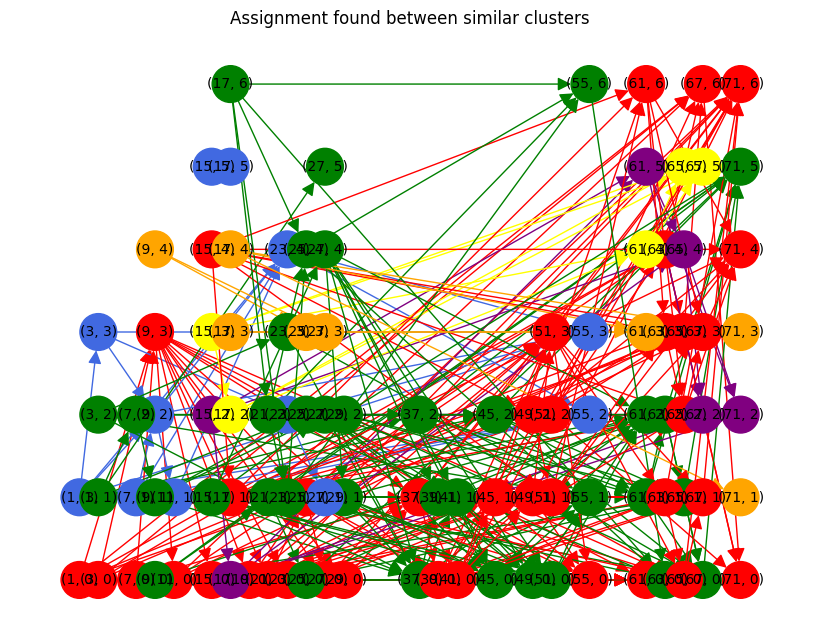

In [15]:
Clusters.plotGraph()

## Graph the final clusters

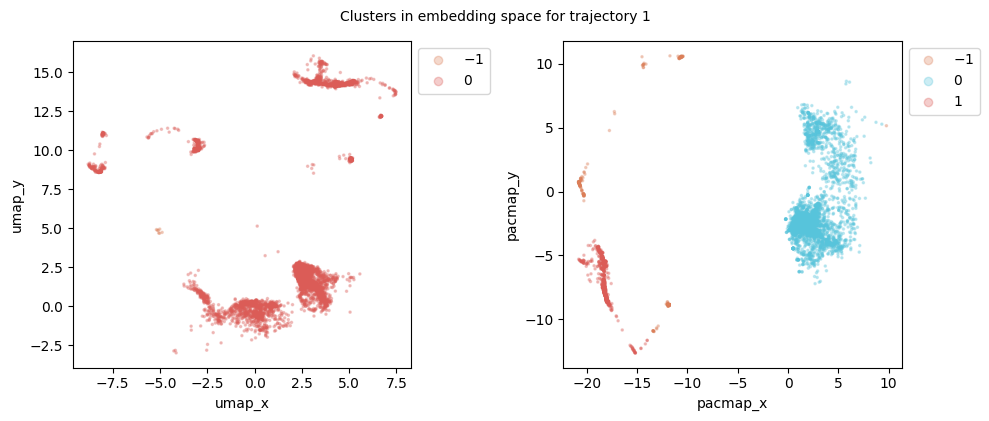

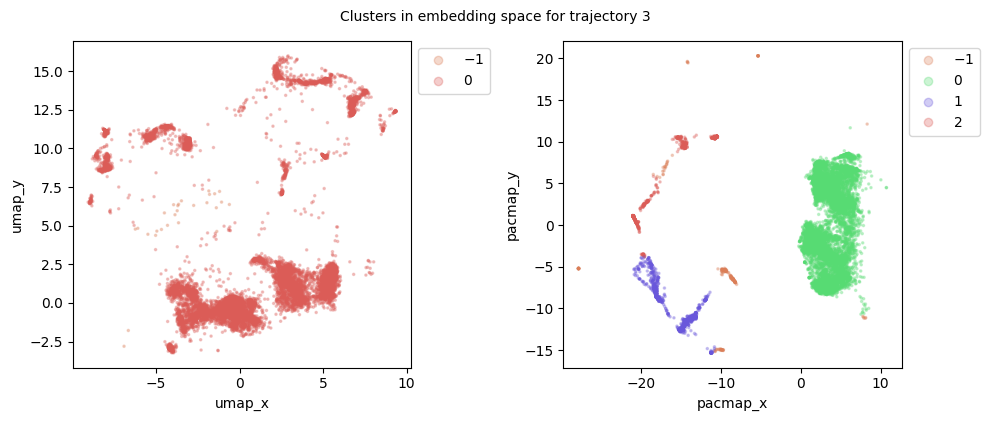

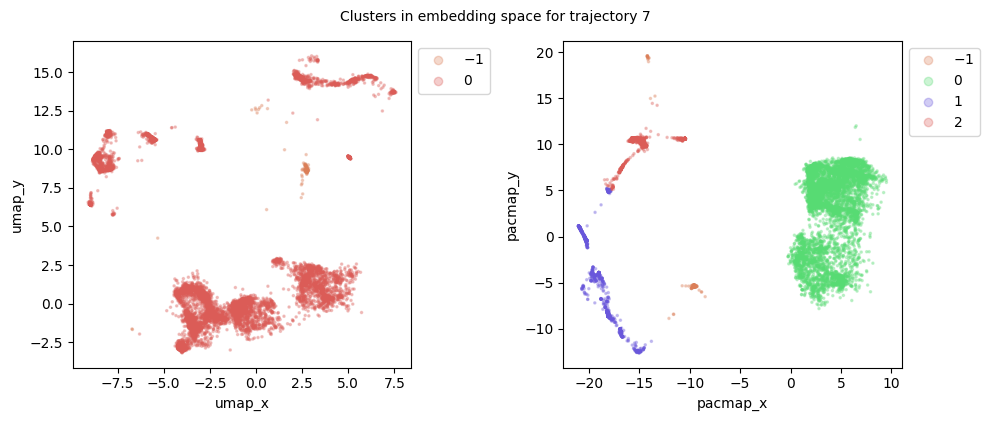

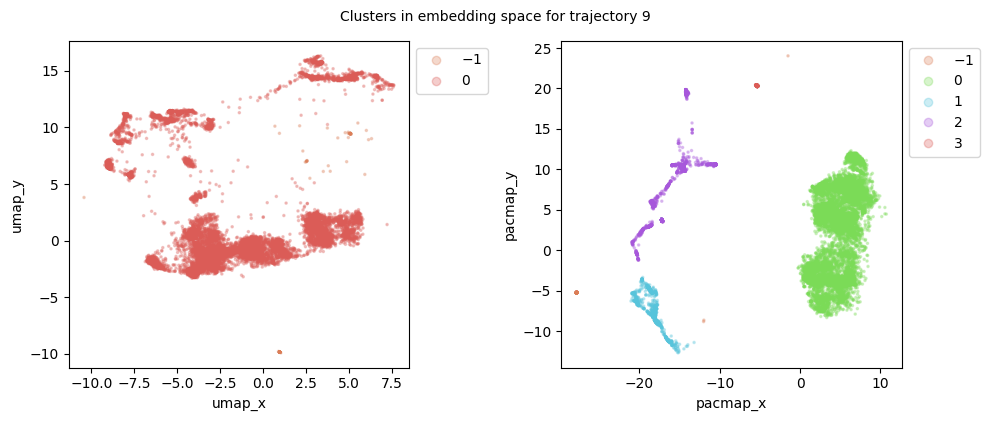

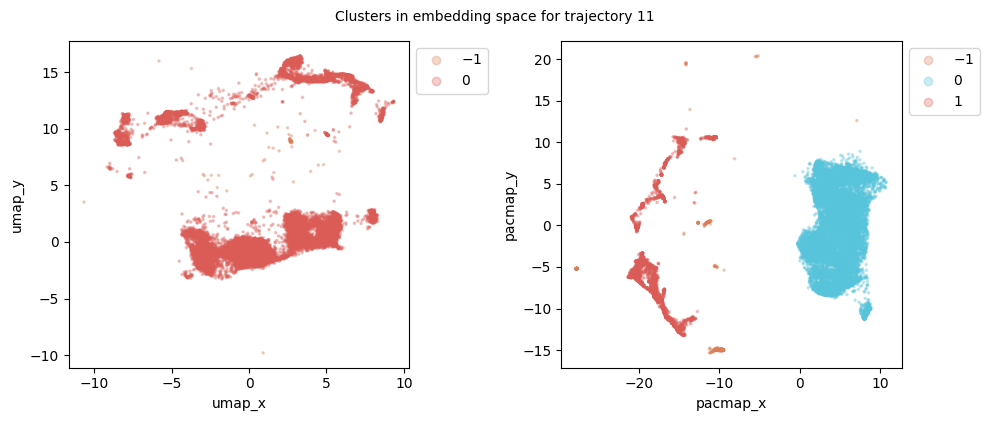

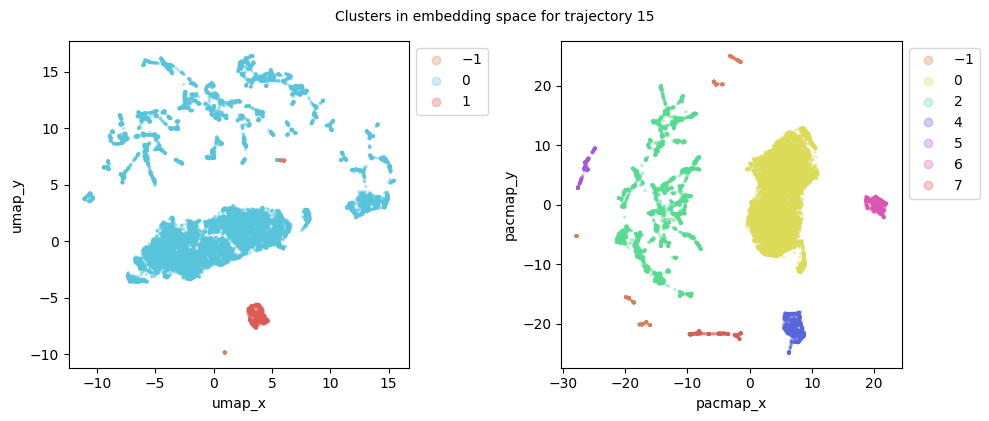

In [16]:
Clusters.plotResults(nfigures=2, 
                     label_color='real_cluster')

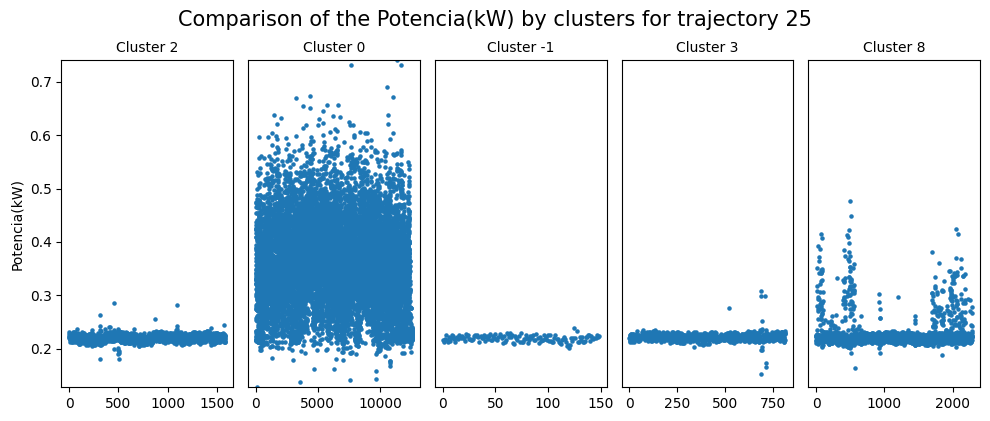

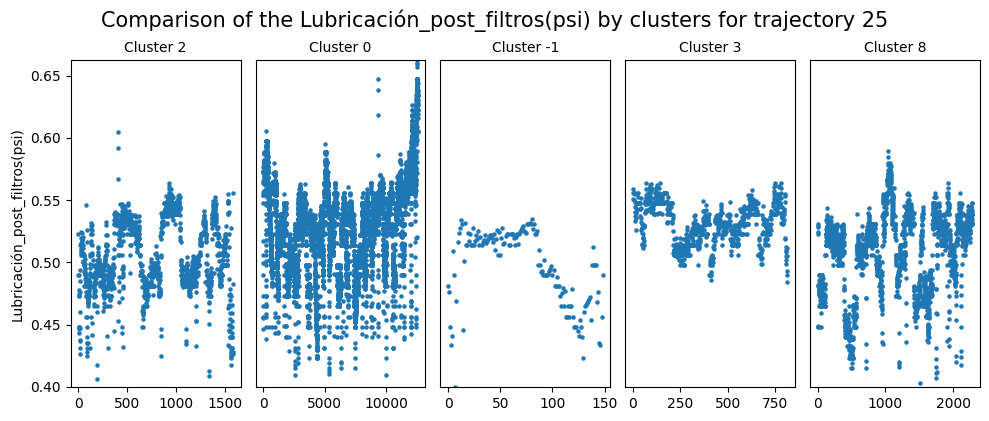

In [28]:
variable = dfManipulableVar.columns[2]
Clusters.plotVarByCluster(idxTrajectory = 10, 
                          variable      = variable, 
                          algorithm     = 'pacmap')

variable = dfManipulableVar.columns[10]
Clusters.plotVarByCluster(idxTrajectory = 10, 
                          variable      = variable, 
                          algorithm     = 'pacmap')